# 06. Interpretabilidad (SHAP y LIME)

SHAP global (summary plot) y local (waterfall, 2 observaciones: una bien clasificada y una con error alto) para la combinación con mayor F1 medio en `05_results_analysis.ipynb` (Random Forest, `class_weight`, `genetic_deap`), más una comparación LIME vs. SHAP para XGBoost sobre una sola observación.

**Alcance:** (provisional)**Alcance y limitaciones:**
- Las secciones 1 a 4 interpretan **una** combinación (la de mayor F1 medio: Random Forest, `class_weight`, `genetic_deap`) en **un** fold externo (el de mayor F1, elegido a posteriori), sobre 100 filas, y comparan LIME con SHAP en **una** observación de XGBoost. Sirven para ilustrar el método, no para generalizar.
- Las secciones 5 y 6 corrigen eso: repiten el análisis en los **3 folds externos**, cada uno con el pipeline reajustado con los hiperparámetros que su propio bucle interno eligió, y comparan LIME con SHAP en **120 observaciones por modelo** (10 al azar de cada celda de la matriz de confusión por fold), para Random Forest y XGBoost.
- Las dos observaciones del waterfall de la sección 4 son casos extremos (probabilidades 0.982 y 0.964), no representativos del conjunto.
- Se interpretan dos de los siete modelos. Los demás no se explican.
- Con variables correlacionadas, SHAP reparte la importancia entre ellas de forma arbitraria. Y con modelos entrenados con `class_weight` o SMOTE las probabilidades no están calibradas: el valor base de 0.5 refleja el balanceo y no la prevalencia real (22 %), así que los aportes no se leen como cambios de riesgo reales.

Trabaja desde `results/experiments_master.csv` (mismo patrón que `05_results_analysis.ipynb`), no depende de nada en memoria de notebooks anteriores. Las secciones 5 y 6 leen los CSV que genera `python -m src.interpretability_multi` (ver `src/interpretability_multi.py`) y dependen de `results/best_per_model.csv` (ver `08_tabla_maestra_svm.ipynb`).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json

import numpy as np

from src import config
from src.data_loader import load_processed_dataset, split_features_target
from src.synthetic_data import generate_synthetic_dataset
from src.preprocessing import remove_duplicate_rows
from src.models import MODEL_REGISTRY
from src.experiment_runner import load_master_table
from src import interpretability as ip

np.random.seed(config.RANDOM_STATE)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

try:
    df = load_processed_dataset()
except FileNotFoundError:
    df = generate_synthetic_dataset()
df, _ = remove_duplicate_rows(df)
X, y = split_features_target(df)

table = load_master_table(config.EXPERIMENTS_MASTER_PATH)
if table.empty:
    raise RuntimeError("La tabla maestra está vacía. Correr primero 04_run_experiments.ipynb.")

C:\Users\valef\anaconda3\envs\creditcard\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Elegir el mejor modelo y ajustar su pipeline

El fold externo usado es el de mejor desempeño (`{metric}_per_fold`, ver columna persistida por `nested_cv.py`); SHAP/LIME se calculan sobre ESE fold de prueba.

In [2]:
metric_for_ranking = config.DEFAULT_SCORING
best_row = table.sort_values(f"{metric_for_ranking}_mean", ascending=False).iloc[0]
best_model = best_row["model"]
best_technique = best_row["technique"]
best_method = best_row["method"]

best_params_per_fold = json.loads(best_row["best_params_per_fold"])
per_fold_metric = json.loads(best_row[f"{metric_for_ranking}_per_fold"])
best_fold_idx = int(np.argmax(per_fold_metric))
best_params = best_params_per_fold[best_fold_idx]

print(f"Mejor modelo: {best_model} | {best_technique} | {best_method} (fold {best_fold_idx})")

spec = MODEL_REGISTRY[best_model]
fitted = ip.fit_explainable_pipeline(
    spec, best_technique, best_params, X, y, best_fold_idx,
    n_outer_folds=int(best_row["n_outer_folds"]),
)
model_step = fitted["pipeline"].named_steps["model"]
print(f"Features post-transformación: {len(fitted['feature_names'])}")

Mejor modelo: random_forest | class_weight | genetic_deap (fold 2)


Features post-transformación: 25


## SHAP global (summary plot)

Sobre una muestra del fold de prueba (ver `interpretability.DEFAULT_N_EXPLAIN`, limitado por costo computacional para modelos no basados en árboles). Las columnas one-hot de `SEX`/`EDUCATION`/`MARRIAGE` se agregan de vuelta a la variable categórica original.

C:\Users\valef\OneDrive\Desktop\Credit_Card_Project\src\interpretability.py:329: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


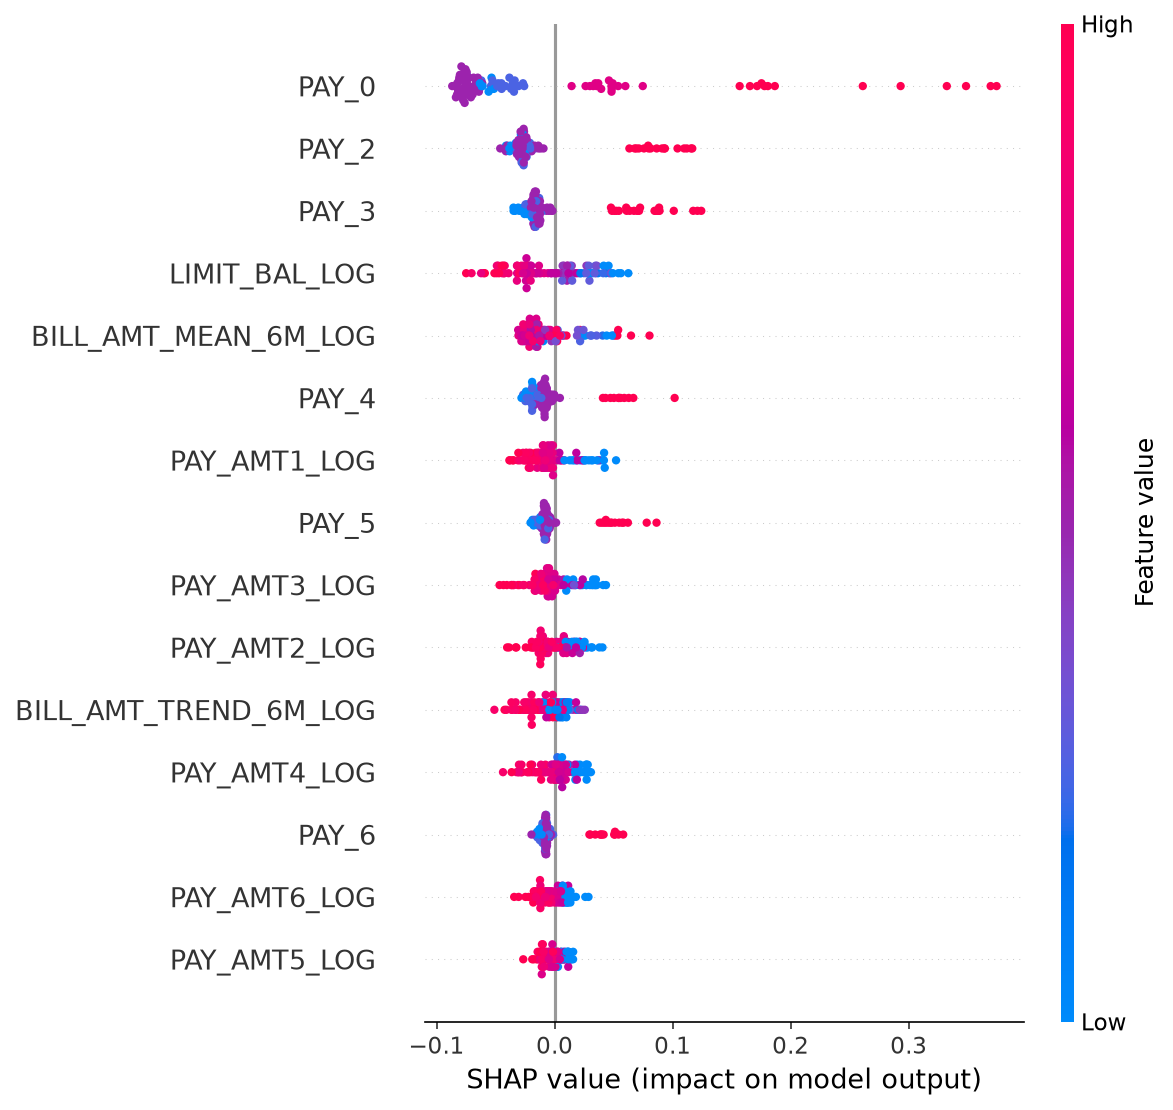

In [3]:
n_explain = min(ip.DEFAULT_N_EXPLAIN, fitted["X_test_t"].shape[0])

shap_values, base_value = ip.compute_shap_values(
    best_model, model_step, fitted["X_train_t"], fitted["X_test_t"][:n_explain]
)
agg_values, agg_names = ip.aggregate_onehot_shap(shap_values, fitted["feature_names"])
display_matrix = ip.build_aggregated_display_matrix(
    fitted["X_test"].iloc[:n_explain], fitted["X_test_t"][:n_explain], fitted["feature_names"]
)

summary_path = config.FIGURES_DIR / f"shap_summary_{best_model}.png"
ip.plot_shap_summary(agg_values, display_matrix, agg_names, save_path=str(summary_path))

from IPython.display import Image, display as ipy_display

ipy_display(Image(filename=str(summary_path)))

- **El historial de pagos domina.** `PAY_0` es la variable más importante, con una diferencia clara frente a las demás. Sus valores altos (meses de atraso) generan los aportes más grandes hacia *default*, de hasta cerca de +0.37. Le siguen `PAY_2` y `PAY_3`, y más abajo `PAY_4`, `PAY_5` y `PAY_6`. En todas ellas, más atraso aumenta el riesgo. Esto coincide con el EDA y, en parte, con la regresión logística base: allí `PAY_0` (+0.52) es el mayor coeficiente entre las variables numéricas, pero el mayor en valor absoluto es `EDUCATION_4` (-0.96). Además, coeficientes lineales y SHAP sobre un bosque no son directamente comparables.
- **Mayor límite de crédito, menor riesgo.** En `LIMIT_BAL_LOG` los valores altos (rojo) quedan a la izquierda, es decir, reducen la probabilidad de *default*. Esto es coherente con la diferencia de límites entre clientes con y sin *default* encontrada en el EDA.
- **Montos pagados.** En las variables `PAY_AMT*_LOG`, los clientes que pagaron más (rojo) tienden a tener aportes negativos, o sea menor riesgo. Su efecto individual es pequeño.
- **Facturación.** `BILL_AMT_MEAN_6M_LOG` aparece en quinto lugar y `BILL_AMT_TREND_6M_LOG` en un nivel más bajo, con un efecto moderado y menos claro que el de los pagos. Esto es consistente con el EDA, donde el monto facturado discriminaba poco entre clases.

## SHAP local: una observación bien clasificada y una con error alto

{'well_classified': 2555, 'high_error': 3936}


well_classified: y_true=1, y_pred=1, proba=0.982


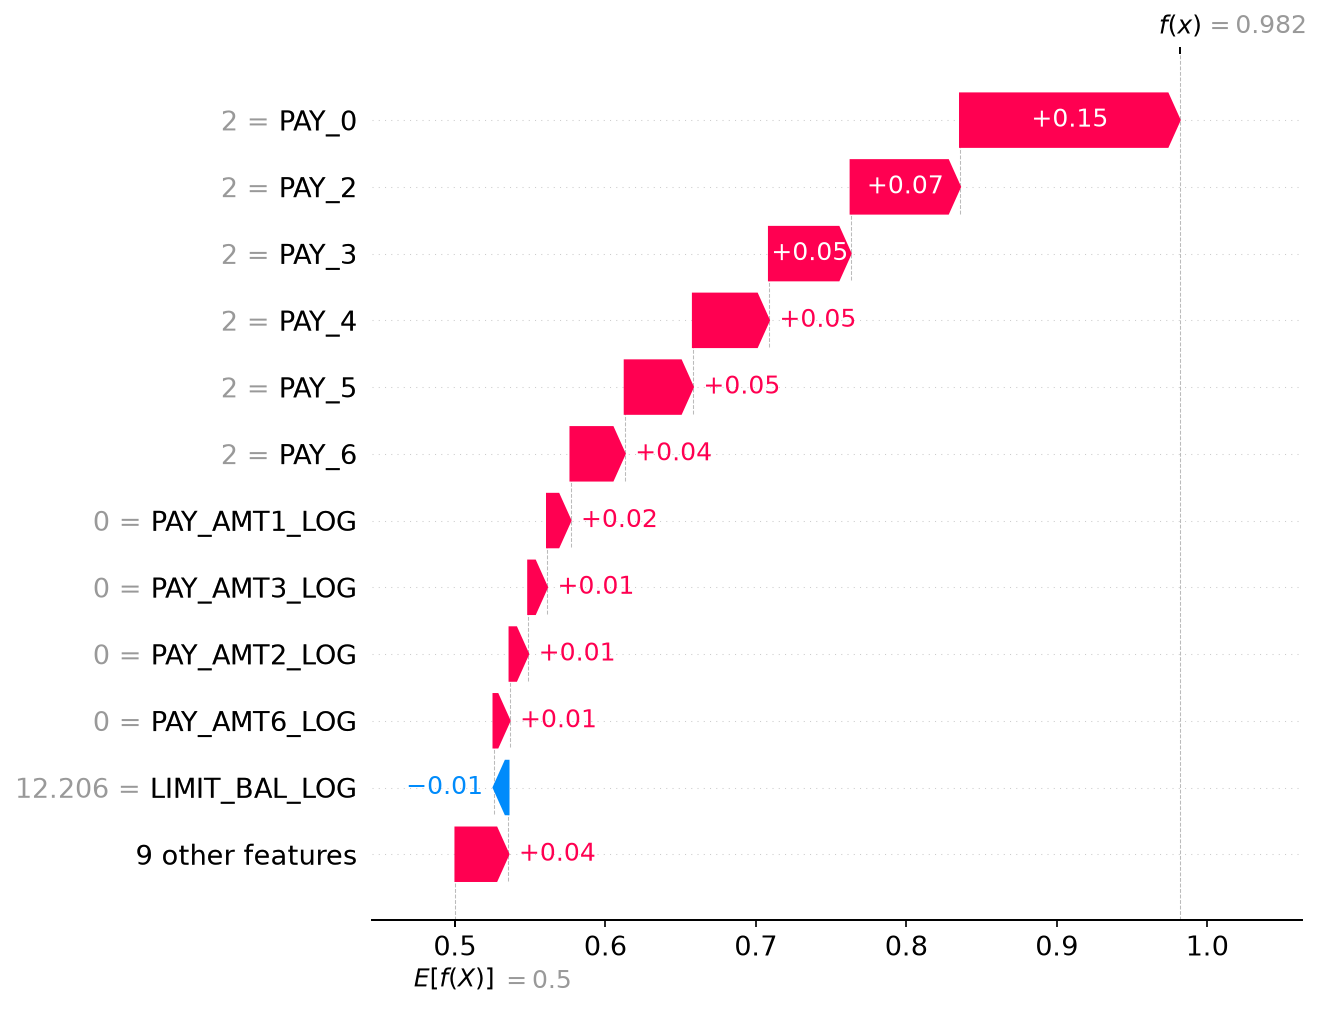

high_error: y_true=0, y_pred=1, proba=0.964


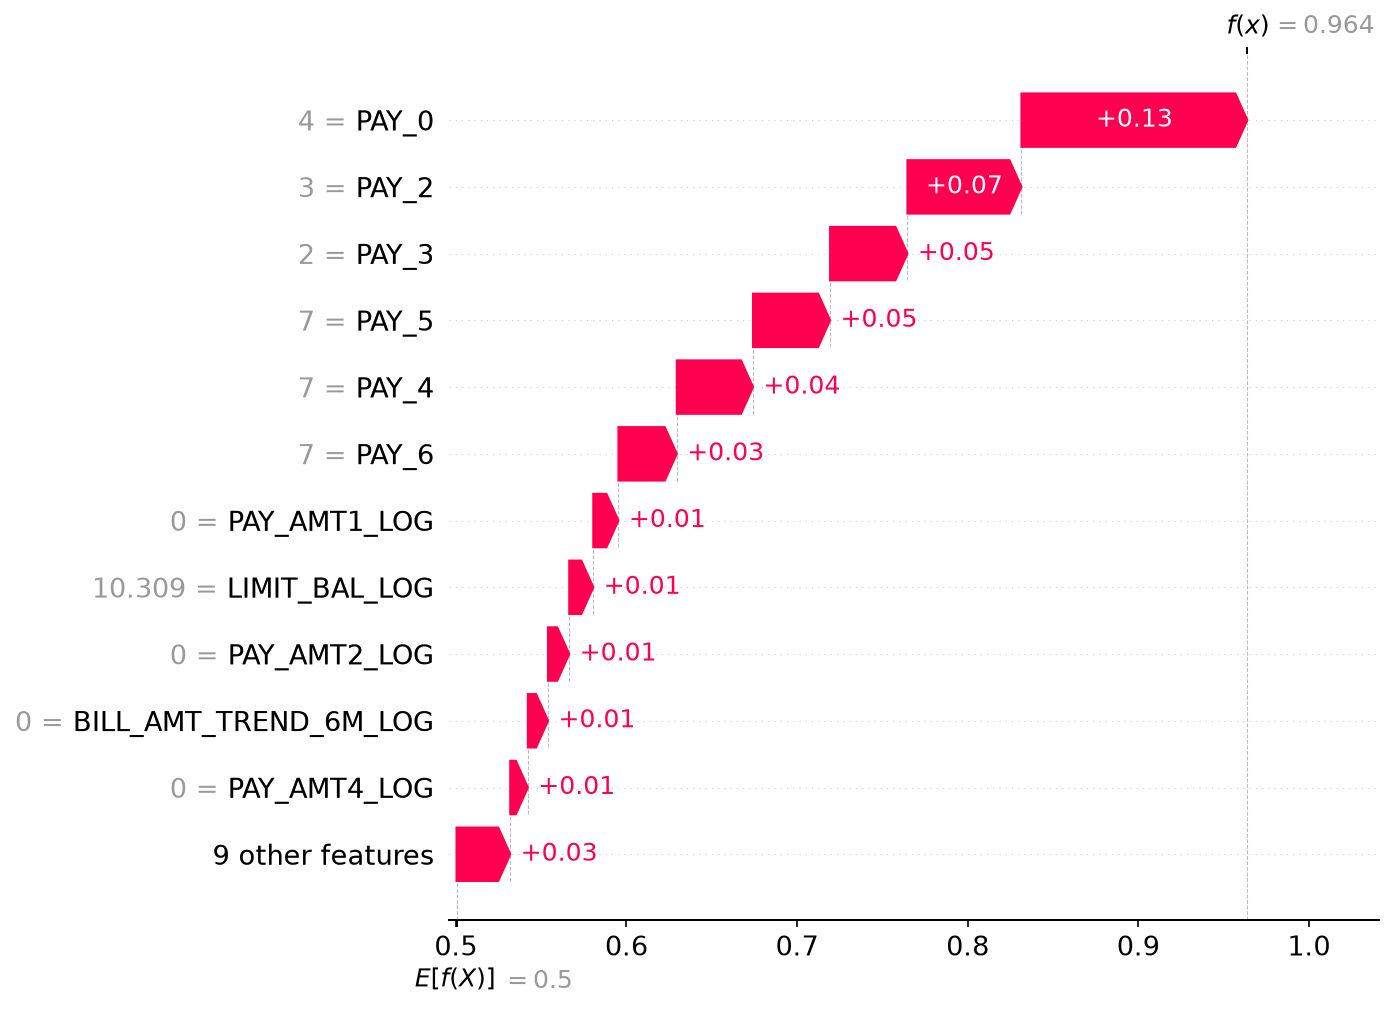

In [4]:
y_pred_test = fitted["pipeline"].predict(fitted["X_test"])
y_proba_test = fitted["pipeline"].predict_proba(fitted["X_test"])[:, 1]
instances = ip.select_representative_instances(fitted["y_test"].to_numpy(), y_pred_test, y_proba_test)
print(instances)

for label, pos in instances.items():
    x_row_t = fitted["X_test_t"][pos : pos + 1]
    sv, bv = ip.compute_shap_values(best_model, model_step, fitted["X_train_t"], x_row_t)
    agg_sv, agg_n = ip.aggregate_onehot_shap(sv, fitted["feature_names"])
    row_display = ip.build_aggregated_display_matrix(
        fitted["X_test"].iloc[pos : pos + 1], x_row_t, fitted["feature_names"]
    )
    waterfall_path = config.FIGURES_DIR / f"shap_waterfall_{best_model}_{label}.png"
    ip.plot_shap_waterfall(agg_sv[0], bv, row_display[0], agg_n, save_path=str(waterfall_path))
    print(
        f"{label}: y_true={fitted['y_test'].iloc[pos]}, y_pred={y_pred_test[pos]}, "
        f"proba={y_proba_test[pos]:.3f}"
    )
    ipy_display(Image(filename=str(waterfall_path)))

Se analizaron dos clientes del pliegue de prueba. El valor base del modelo es 0.5 y cada barra indica cuánto sube o baja la probabilidad predicha.

**1. Cliente bien clasificado** (*default* real = 1, predicho = 1, probabilidad = 0.982)

- Tiene un atraso de 2 meses en `PAY_0` y también en `PAY_2` a `PAY_6`, es decir, atrasos en los seis meses.
- Las seis variables `PAY` suman cerca de +0.41, lo que explica casi todo el aumento de 0.5 a 0.982. El mayor aporte es el de `PAY_0` (+0.15).
- No registra pagos (`PAY_AMT_LOG = 0`), lo que suma un poco más al riesgo.
- Su límite de crédito (`LIMIT_BAL_LOG` = 12.206, cercano a 200,000) es el único factor que lo reduce, y solo en -0.01.

El modelo acierta con mucha seguridad porque todas las señales importantes apuntan en la misma dirección.

**2. Cliente con error alto** (*default* real = 0, predicho = 1, probabilidad = 0.964)

- Es un falso positivo. Tiene atrasos en todos los meses (`PAY_0` = 4, `PAY_2` = 3, `PAY_3` = 2 y `PAY_4`, `PAY_5`, `PAY_6` = 7) y sin pagos registrados.
- Las seis variables `PAY` suman cerca de +0.37, con `PAY_0` como mayor aporte (+0.13). Según su historial, el modelo lo considera casi seguro de caer en *default*.
- Su historial es poco habitual: los atrasos pasan de 2 a 7 meses de un mes a otro. Esto podría indicar un registro atípico o con errores, pero con estos datos no se puede confirmar.

El error no parece venir de una falla del modelo, sino de un cliente que, con ese historial, no incumplió. Esto es consistente con el ruido que ya se había detectado en el EDA: hay clientes con las mismas variables y etiquetas distintas, por lo que ningún modelo puede acertar en todos los casos.

Ambos clientes son casos extremos (probabilidades 0.982 y 0.964), elegidos para ilustrar, y no representan el comportamiento típico del modelo. Como el modelo se entrenó con `class_weight`, esas probabilidades tampoco están calibradas.


## LIME vs. SHAP (específicamente para XGBoost)

Si el mejor modelo ya es XGBoost, esta sección reutiliza el mismo ajuste de arriba; si no, ajusta la mejor combinación de XGBoost por separado (el curso pide esta comparación puntualmente para XGBoost, más allá de cuál haya resultado ser el mejor modelo global). Se explica una sola observación (`high_error`), por lo que la comparación es ilustrativa.

In [5]:
xgb_rows = table[table["model"] == "xgboost"]

if xgb_rows.empty:
    print(
        "No hay corridas de XGBoost en la tabla maestra todavía: "
        "correr 04_run_experiments.ipynb incluyendo xgboost para esta sección."
    )
else:
    xgb_best_row = xgb_rows.sort_values(f"{metric_for_ranking}_mean", ascending=False).iloc[0]
    xgb_technique = xgb_best_row["technique"]
    xgb_best_params_per_fold = json.loads(xgb_best_row["best_params_per_fold"])
    xgb_per_fold_metric = json.loads(xgb_best_row[f"{metric_for_ranking}_per_fold"])
    xgb_fold_idx = int(np.argmax(xgb_per_fold_metric))
    xgb_best_params = xgb_best_params_per_fold[xgb_fold_idx]

    xgb_spec = MODEL_REGISTRY["xgboost"]
    xgb_fitted = ip.fit_explainable_pipeline(
        xgb_spec, xgb_technique, xgb_best_params, X, y, xgb_fold_idx,
        n_outer_folds=int(xgb_best_row["n_outer_folds"]),
    )
    xgb_model_step = xgb_fitted["pipeline"].named_steps["model"]

    xgb_y_pred = xgb_fitted["pipeline"].predict(xgb_fitted["X_test"])
    xgb_y_proba = xgb_fitted["pipeline"].predict_proba(xgb_fitted["X_test"])[:, 1]
    xgb_instances = ip.select_representative_instances(
        xgb_fitted["y_test"].to_numpy(), xgb_y_pred, xgb_y_proba
    )

    pos = xgb_instances["high_error"]
    x_row_t = xgb_fitted["X_test_t"][pos : pos + 1]

    lime_exp = ip.explain_with_lime(
        xgb_model_step, xgb_fitted["X_train_t"], xgb_fitted["feature_names"], x_row_t
    )
    sv, bv = ip.compute_shap_values("xgboost", xgb_model_step, xgb_fitted["X_train_t"], x_row_t)
    comparison_table = ip.compare_shap_lime(sv[0], lime_exp, xgb_fitted["feature_names"])

    print(f"Observación 'high_error' (XGBoost, {xgb_technique}, fold {xgb_fold_idx}):")
    display(comparison_table)

Observación 'high_error' (XGBoost, class_weight, fold 2):


,feature,shap_value,lime_weight
0,remainder__PAY_0,1.245319,0.091352
1,remainder__PAY_2,0.314957,0.043534
2,remainder__PAY_3,0.232570,0.071247
3,remainder__PAY_6,0.178103,0.034266
4,remainder__PAY_4,0.173505,0.056531
5,remainder__PAY_5,0.133808,0.025168
6,remainder__BILL_AMT_TREND_6M_LOG,0.051481,0.021247
7,remainder__BILL_AMT_MEAN_6M_LOG,-0.048345,-0.025667
8,remainder__LIMIT_BAL_LOG,0.046637,NaN
9,remainder__AGE,0.042024,NaN


### Discusión: ¿cuándo divergen LIME y SHAP?

- **LIME** ajusta un modelo sustituto LINEAL (regularizado) sobre muestras perturbadas alrededor de la observación, ponderadas por cercanía: una aproximación local cuya validez depende del ancho del kernel y el número de muestras perturbadas.
- **SHAP** calcula valores de Shapley (teoría de juegos cooperativos): el aporte marginal promedio de cada feature sobre todas las coaliciones posibles. Para árboles, `TreeExplainer` los calcula de forma EXACTA, y satisface axiomas de consistencia que LIME no garantiza.

**Divergen cuando:**
1. **Features correlacionadas** (ej. el bloque `BILL_AMT1`-`BILL_AMT6`, VIF alto según el EDA): SHAP reparte el crédito entre ellas; LIME (Lasso) puede anular una y sobre-atribuir a la otra.
2. **No linealidad local fuerte** (ej. el efecto no lineal de `PAY_0` que el EDA ya detectó): un sustituto lineal como el de LIME la aproxima mal; SHAP (exacto para árboles) la sigue reflejando correctamente.
3. **Sensibilidad a hiperparámetros de LIME** (ancho del kernel, nº de muestras): puede cambiar el ranking entre corridas; SHAP/TreeExplainer es determinístico.

Limitación de la tabla anterior: es una sola observación de XGBoost, y `shap_value` está en escala de log-odds (margen de XGBoost) mientras que `lime_weight` está en escala de probabilidad, por lo que solo se pueden comparar signos y orden, no magnitudes.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from src import interpretability_multi as im

INTERP_DIR = config.RESULTS_DIR / "interpretability"
MODELS = ("random_forest", "xgboost")
importance = {m: pd.read_csv(INTERP_DIR / f"shap_importance_by_fold_{m}.csv") for m in MODELS}
agreement = {m: pd.read_csv(INTERP_DIR / f"lime_vs_shap_{m}.csv") for m in MODELS}
best_table = pd.read_csv(config.RESULTS_DIR / "best_per_model.csv").set_index("model")
for m in MODELS:
    print(f"{m}: combinación {best_table.loc[m, 'technique']} | {best_table.loc[m, 'method']}; "
          f"{importance[m]['n_explained'].iloc[0]} filas explicadas por fold, "
          f"{len(agreement[m])} observaciones para LIME vs. SHAP")

random_forest: combinación class_weight | genetic_deap; 300 filas explicadas por fold, 120 observaciones para LIME vs. SHAP
xgboost: combinación class_weight | bayesian_optuna; 300 filas explicadas por fold, 120 observaciones para LIME vs. SHAP


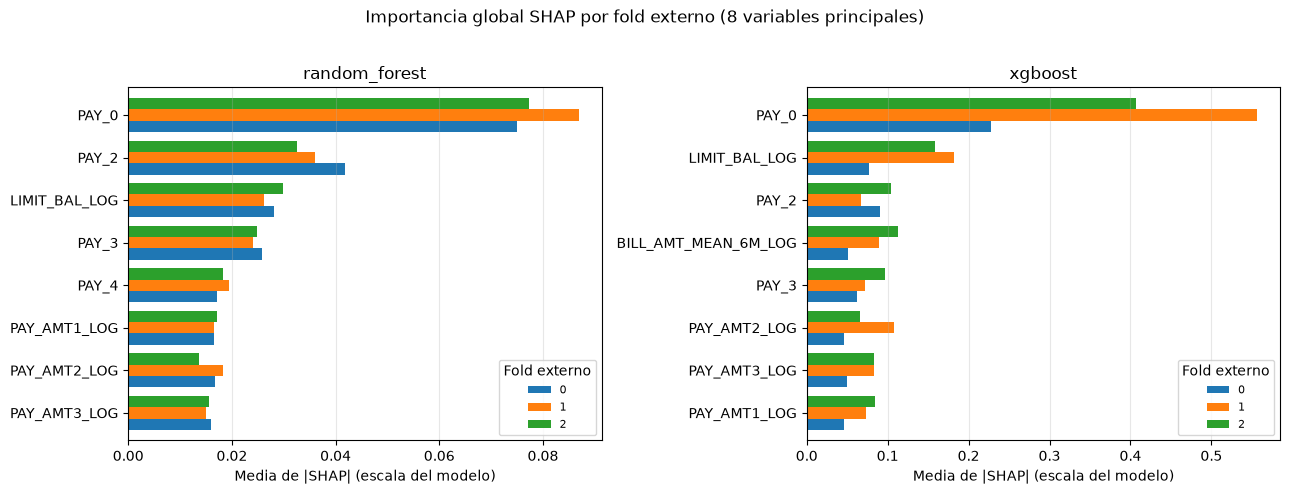


random_forest: Spearman medio entre folds = 0.951; Jaccard medio del top-5 = 1.000; siempre en el top-5: ['LIMIT_BAL_LOG', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4']


fold,0,1,2
fold,,,
0,1.000,0.967,0.956
1,0.967,1.000,0.929
2,0.956,0.929,1.000



xgboost: Spearman medio entre folds = 0.887; Jaccard medio del top-5 = 0.619; siempre en el top-5: ['BILL_AMT_MEAN_6M_LOG', 'LIMIT_BAL_LOG', 'PAY_0']


fold,0,1,2
fold,,,
0,1.000,0.896,0.919
1,0.896,1.000,0.847
2,0.919,0.847,1.000


In [7]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(6.5 * len(MODELS), 4.8))
for ax, m in zip(axes, MODELS):
    imp = importance[m]
    top = imp.groupby("feature")["mean_abs_shap"].mean().nlargest(8).index[::-1]
    pivot = imp.pivot(index="feature", columns="fold", values="mean_abs_shap").loc[top]
    pivot.plot.barh(ax=ax, width=0.8)
    ax.set_title(m)
    ax.set_xlabel("Media de |SHAP| (escala del modelo)")
    ax.set_ylabel("")
    ax.legend(title="Fold externo", fontsize=8)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Importancia global SHAP por fold externo (8 variables principales)", y=1.02)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "shap_importance_by_fold.png", dpi=150, bbox_inches="tight")
plt.show()

for m in MODELS:
    st = im.importance_stability(importance[m])
    print(f"\n{m}: Spearman medio entre folds = {st['spearman_mean_offdiag']:.3f}; "
          f"Jaccard medio del top-5 = {st['topk_jaccard_mean_offdiag']:.3f}; "
          f"siempre en el top-5: {st['topk_always']}")
    display(st["spearman"].round(3))

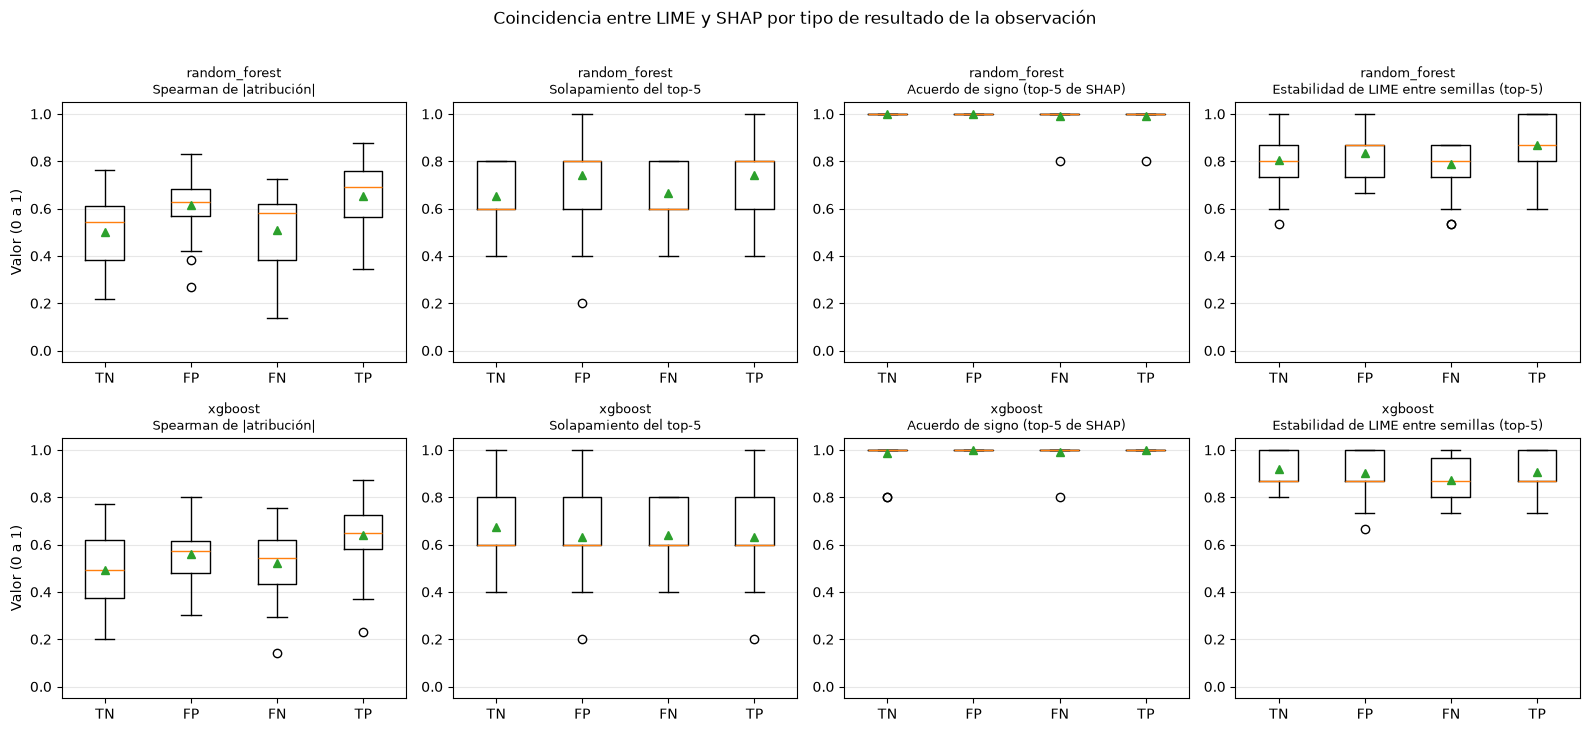


random_forest (n = 120 observaciones, 3 folds)


spearman_abs               top5_overlap               sign_agreement_topk  \
            mean    std median         mean    std median                mean   
FN         0.509  0.166  0.581        0.667  0.132    0.6               0.993   
FP         0.614  0.125  0.630        0.740  0.167    0.8               1.000   
TN         0.501  0.145  0.541        0.653  0.128    0.6               1.000   
TP         0.654  0.151  0.690        0.740  0.175    0.8               0.993   
ALL        0.569  0.160  0.595        0.700  0.156    0.8               0.997   

                  lime_seed_topk_overlap                
       std median                   mean    std median  
FN   0.037    1.0                  0.787  0.097  0.800  
FP   0.000    1.0                  0.836  0.102  0.867  
TN   0.000    1.0                  0.807  0.128  0.800  
TP   0.037    1.0                  0.869  0.114  0.867  
ALL  0.026    1.0                  0.824  0.114  0.867


xgboost (n = 120 observaciones, 3 folds)


spearman_abs               top5_overlap               sign_agreement_topk  \
            mean    std median         mean    std median                mean   
FN         0.522  0.145  0.542        0.640  0.161    0.6               0.993   
FP         0.560  0.120  0.575        0.633  0.167    0.6               1.000   
TN         0.492  0.168  0.493        0.673  0.153    0.6               0.987   
TP         0.639  0.141  0.650        0.633  0.175    0.6               1.000   
ALL        0.553  0.153  0.567        0.645  0.163    0.6               0.995   

                  lime_seed_topk_overlap                
       std median                   mean    std median  
FN   0.037    1.0                  0.871  0.091  0.867  
FP   0.000    1.0                  0.902  0.094  0.867  
TN   0.051    1.0                  0.920  0.079  0.867  
TP   0.000    1.0                  0.907  0.085  0.867  
ALL  0.031    1.0                  0.900  0.088  0.867

In [8]:
METRICS = {
    "spearman_abs": "Spearman de |atribución|",
    "top5_overlap": "Solapamiento del top-5",
    "sign_agreement_topk": "Acuerdo de signo (top-5 de SHAP)",
    "lime_seed_topk_overlap": "Estabilidad de LIME entre semillas (top-5)",
}
fig, axes = plt.subplots(len(MODELS), len(METRICS), figsize=(4 * len(METRICS), 3.6 * len(MODELS)), sharey="col")
order = ["TN", "FP", "FN", "TP"]
for i, m in enumerate(MODELS):
    for j, (col, title) in enumerate(METRICS.items()):
        ax = axes[i, j]
        data = [agreement[m].loc[agreement[m]["outcome"] == o, col].dropna() for o in order]
        ax.boxplot(data, tick_labels=order, showmeans=True)
        ax.set_title(f"{m}\n{title}", fontsize=9)
        ax.set_ylim(-0.05, 1.05)
        ax.grid(axis="y", alpha=0.3)
        if j == 0:
            ax.set_ylabel("Valor (0 a 1)")
fig.suptitle("Coincidencia entre LIME y SHAP por tipo de resultado de la observación", y=1.01)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "lime_vs_shap_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

for m in MODELS:
    print(f"\n{m} (n = {len(agreement[m])} observaciones, 3 folds)")
    display(im.summarize_agreement(agreement[m]).round(3))

<!-- multi-fold -->
# Correcciones: SHAP y LIME con más de un fold y más de una observación

La versión anterior de este notebook explicaba un solo fold con 100 filas y comparaba LIME con SHAP en una sola observación. Con eso no se puede decir si la explicación es estable ni si los dos métodos coinciden en general. Las dos secciones siguientes responden esas dos preguntas con el código de `src/interpretability_multi.py`.

Para cada modelo se toma su mejor combinación según `results/best_per_model.csv`: Random Forest con `class_weight` y `genetic_deap`, y XGBoost con `class_weight` y `bayesian_optuna`.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from src import interpretability_multi as im

INTERP_DIR = config.RESULTS_DIR / "interpretability"
MODELS = ("random_forest", "xgboost")
importance = {m: pd.read_csv(INTERP_DIR / f"shap_importance_by_fold_{m}.csv") for m in MODELS}
agreement = {m: pd.read_csv(INTERP_DIR / f"lime_vs_shap_{m}.csv") for m in MODELS}
best_table = pd.read_csv(config.RESULTS_DIR / "best_per_model.csv").set_index("model")
for m in MODELS:
    print(f"{m}: combinación {best_table.loc[m, 'technique']} | {best_table.loc[m, 'method']}; "
          f"{importance[m]['n_explained'].iloc[0]} filas explicadas por fold, "
          f"{len(agreement[m])} observaciones para LIME vs. SHAP")

random_forest: combinación class_weight | genetic_deap; 300 filas explicadas por fold, 120 observaciones para LIME vs. SHAP
xgboost: combinación class_weight | bayesian_optuna; 300 filas explicadas por fold, 120 observaciones para LIME vs. SHAP


<!-- multi-fold -->
## 5. SHAP global en los 3 folds externos

**Procedimiento.** En cada fold externo se reajusta el pipeline completo con los `best_params` que eligió el bucle interno de ese fold, y se calculan los valores SHAP (`TreeExplainer`, exacto) sobre 300 filas al azar del conjunto de prueba de ese mismo fold. La importancia de una variable es la media de |SHAP| sobre esas filas, y las columnas one-hot de `SEX`, `EDUCATION` y `MARRIAGE` se suman de vuelta a su variable original. Después se mide qué tan parecido queda el ranking entre folds con la correlación de Spearman y con el solapamiento (Jaccard) del top 5.

Las magnitudes de distintos folds no son estrictamente comparables, porque cada fold usa un modelo con hiperparámetros distintos. Por eso la estabilidad se juzga con el orden de las variables y no con el valor absoluto.

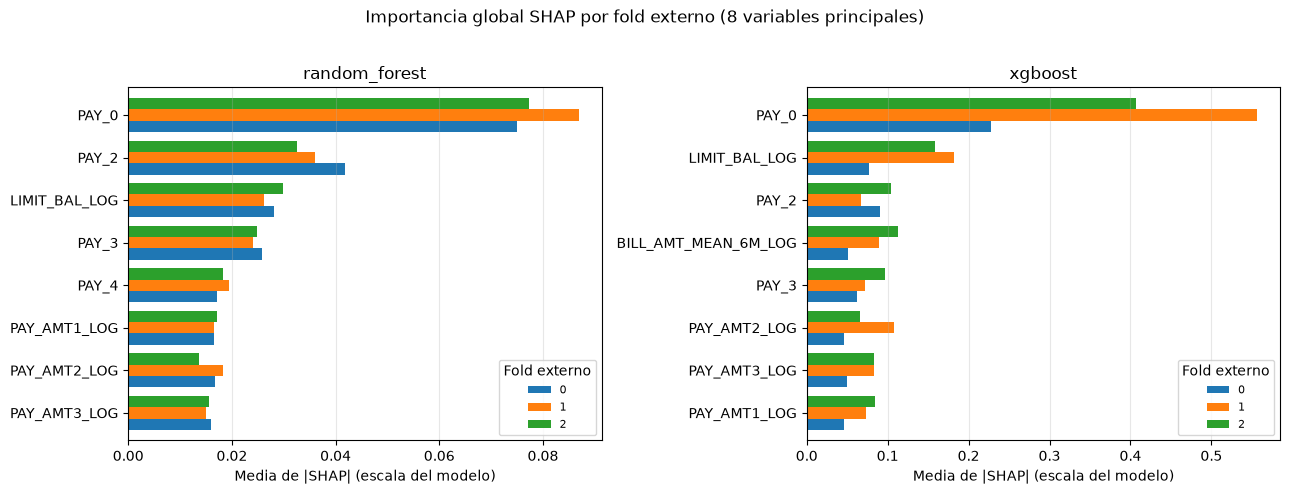


random_forest: Spearman medio entre folds = 0.951; Jaccard medio del top-5 = 1.000; siempre en el top-5: ['LIMIT_BAL_LOG', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4']


fold,0,1,2
fold,,,
0,1.000,0.967,0.956
1,0.967,1.000,0.929
2,0.956,0.929,1.000



xgboost: Spearman medio entre folds = 0.887; Jaccard medio del top-5 = 0.619; siempre en el top-5: ['BILL_AMT_MEAN_6M_LOG', 'LIMIT_BAL_LOG', 'PAY_0']


fold,0,1,2
fold,,,
0,1.000,0.896,0.919
1,0.896,1.000,0.847
2,0.919,0.847,1.000


In [10]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(6.5 * len(MODELS), 4.8))
for ax, m in zip(axes, MODELS):
    imp = importance[m]
    top = imp.groupby("feature")["mean_abs_shap"].mean().nlargest(8).index[::-1]
    pivot = imp.pivot(index="feature", columns="fold", values="mean_abs_shap").loc[top]
    pivot.plot.barh(ax=ax, width=0.8)
    ax.set_title(m)
    ax.set_xlabel("Media de |SHAP| (escala del modelo)")
    ax.set_ylabel("")
    ax.legend(title="Fold externo", fontsize=8)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Importancia global SHAP por fold externo (8 variables principales)", y=1.02)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "shap_importance_by_fold.png", dpi=150, bbox_inches="tight")
plt.show()

for m in MODELS:
    st = im.importance_stability(importance[m])
    print(f"\n{m}: Spearman medio entre folds = {st['spearman_mean_offdiag']:.3f}; "
          f"Jaccard medio del top-5 = {st['topk_jaccard_mean_offdiag']:.3f}; "
          f"siempre en el top-5: {st['topk_always']}")
    display(st["spearman"].round(3))

<!-- multi-fold -->
**Lectura.**
- **Random Forest es estable.** El top 5 es el mismo en los tres folds y en el mismo orden (`PAY_0`, `PAY_2`, `LIMIT_BAL_LOG`, `PAY_3`, `PAY_4`): Jaccard 1.0 y Spearman medio de 0.951 sobre el ranking completo. Los valores de `PAY_0` son casi iguales entre folds (0.075, 0.087 y 0.077). La conclusión de la sección 3 (el historial de pagos domina) no depende del fold elegido.
- **XGBoost es estable en lo principal y menos en el resto.** `PAY_0` es la primera variable en los tres folds y `LIMIT_BAL_LOG` y `BILL_AMT_MEAN_6M_LOG` están siempre en el top 5. Pero el top 5 completo cambia entre folds (Jaccard medio 0.619): `PAY_2` y `PAY_3` salen del top 5 en el fold 1, y entran `PAY_AMT2_LOG` y `PAY_AMT3_LOG`. El Spearman medio sobre todas las variables es de 0.887.
- **La magnitud de `PAY_0` en XGBoost varía mucho entre folds** (0.228, 0.557 y 0.407 en log-odds). Es esperable, porque cada fold eligió hiperparámetros distintos, así que no conviene comparar magnitudes entre folds, solo el orden.
- **Qué se puede afirmar y qué no.** El historial de pagos (`PAY_0` primero, luego `PAY_2` y `PAY_3`) y el límite de crédito como segundo o tercer factor se sostienen en los tres folds y en los dos modelos. El orden fino de las variables de montos (`PAY_AMT*_LOG`, `BILL_AMT_MEAN_6M_LOG`) no es estable en XGBoost y no debe interpretarse.

<!-- multi-fold -->
## 6. LIME frente a SHAP en 120 observaciones por modelo

**Procedimiento.** En cada fold externo se toman 10 observaciones al azar de cada celda de la matriz de confusión (verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos), no solo los casos extremos. Para cada una se calcula el SHAP exacto y la explicación de LIME (10 variables, sobre el mismo espacio transformado que ve el modelo) y se mide:

- **Spearman de |atribución|:** correlación entre el orden de importancia de SHAP y el de LIME sobre todas las variables (las que LIME no reporta valen 0).
- **Solapamiento del top 5:** fracción de las 5 variables principales de SHAP que también están entre las 5 principales de LIME.
- **Acuerdo de signo:** entre las variables del top 5 de SHAP que LIME también reporta, fracción en que ambos métodos coinciden en el signo del efecto.
- **Estabilidad de LIME entre semillas:** LIME se corre con 3 semillas y se mide el solapamiento medio del top 5 entre pares de semillas. Sirve para saber cuánta divergencia con SHAP puede ser simple ruido de LIME.

SHAP está en escala de log-odds (XGBoost) o de probabilidad (Random Forest) y LIME en escala de probabilidad, por eso solo se comparan orden y signo.

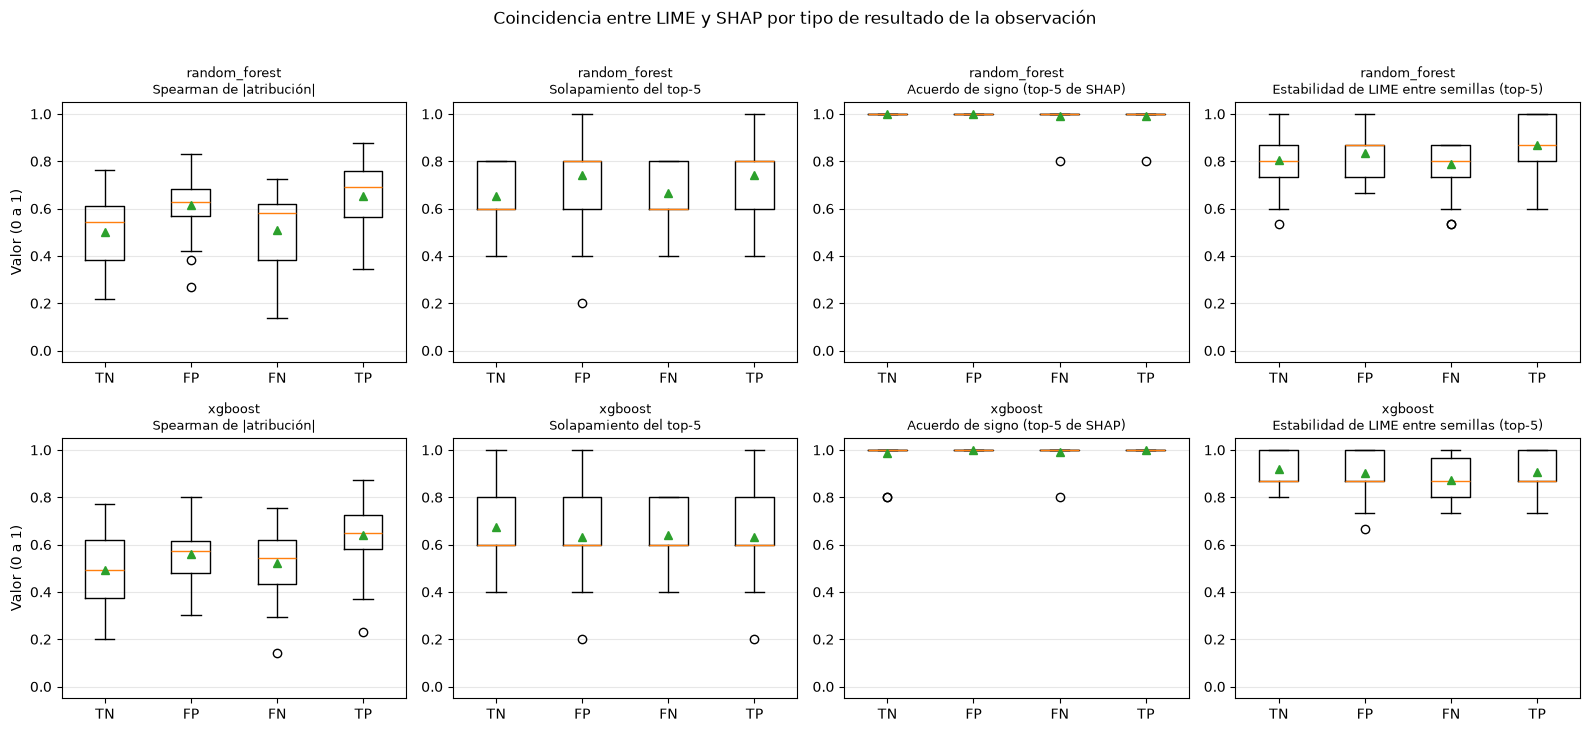


random_forest (n = 120 observaciones, 3 folds)


spearman_abs               top5_overlap               sign_agreement_topk  \
            mean    std median         mean    std median                mean   
FN         0.509  0.166  0.581        0.667  0.132    0.6               0.993   
FP         0.614  0.125  0.630        0.740  0.167    0.8               1.000   
TN         0.501  0.145  0.541        0.653  0.128    0.6               1.000   
TP         0.654  0.151  0.690        0.740  0.175    0.8               0.993   
ALL        0.569  0.160  0.595        0.700  0.156    0.8               0.997   

                  lime_seed_topk_overlap                
       std median                   mean    std median  
FN   0.037    1.0                  0.787  0.097  0.800  
FP   0.000    1.0                  0.836  0.102  0.867  
TN   0.000    1.0                  0.807  0.128  0.800  
TP   0.037    1.0                  0.869  0.114  0.867  
ALL  0.026    1.0                  0.824  0.114  0.867


xgboost (n = 120 observaciones, 3 folds)


spearman_abs               top5_overlap               sign_agreement_topk  \
            mean    std median         mean    std median                mean   
FN         0.522  0.145  0.542        0.640  0.161    0.6               0.993   
FP         0.560  0.120  0.575        0.633  0.167    0.6               1.000   
TN         0.492  0.168  0.493        0.673  0.153    0.6               0.987   
TP         0.639  0.141  0.650        0.633  0.175    0.6               1.000   
ALL        0.553  0.153  0.567        0.645  0.163    0.6               0.995   

                  lime_seed_topk_overlap                
       std median                   mean    std median  
FN   0.037    1.0                  0.871  0.091  0.867  
FP   0.000    1.0                  0.902  0.094  0.867  
TN   0.051    1.0                  0.920  0.079  0.867  
TP   0.000    1.0                  0.907  0.085  0.867  
ALL  0.031    1.0                  0.900  0.088  0.867

In [11]:
METRICS = {
    "spearman_abs": "Spearman de |atribución|",
    "top5_overlap": "Solapamiento del top-5",
    "sign_agreement_topk": "Acuerdo de signo (top-5 de SHAP)",
    "lime_seed_topk_overlap": "Estabilidad de LIME entre semillas (top-5)",
}
fig, axes = plt.subplots(len(MODELS), len(METRICS), figsize=(4 * len(METRICS), 3.6 * len(MODELS)), sharey="col")
order = ["TN", "FP", "FN", "TP"]
for i, m in enumerate(MODELS):
    for j, (col, title) in enumerate(METRICS.items()):
        ax = axes[i, j]
        data = [agreement[m].loc[agreement[m]["outcome"] == o, col].dropna() for o in order]
        ax.boxplot(data, tick_labels=order, showmeans=True)
        ax.set_title(f"{m}\n{title}", fontsize=9)
        ax.set_ylim(-0.05, 1.05)
        ax.grid(axis="y", alpha=0.3)
        if j == 0:
            ax.set_ylabel("Valor (0 a 1)")
fig.suptitle("Coincidencia entre LIME y SHAP por tipo de resultado de la observación", y=1.01)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "lime_vs_shap_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

for m in MODELS:
    print(f"\n{m} (n = {len(agreement[m])} observaciones, 3 folds)")
    display(im.summarize_agreement(agreement[m]).round(3))

<!-- multi-fold -->
**Lectura** (120 observaciones por modelo, 3 folds).

| Medida | Random Forest | XGBoost |
|---|---|---|
| Spearman de \|atribución\|, media (desviación) | 0.569 (0.160) | 0.553 (0.153) |
| Solapamiento del top 5, media | 0.700 | 0.645 |
| Acuerdo de signo en el top 5, media | 0.997 | 0.995 |
| Estabilidad de LIME entre semillas (top 5), media | 0.824 | 0.900 |

- **Coinciden casi siempre en la dirección del efecto.** En el 98 % de las observaciones de Random Forest y el 97.5 % de las de XGBoost el acuerdo de signo es total, y el mínimo observado es 0.8 (una variable de cinco en desacuerdo).
- **Coinciden menos en el orden.** En promedio comparten entre 3 y 4 de las 5 variables principales (0.70 y 0.645), y la correlación de orden es moderada (cerca de 0.55). En 7.5 % (Random Forest) y 8.3 % (XGBoost) de las observaciones el Spearman es menor que 0.3, es decir, los dos métodos casi no se parecen.
- **Una parte de la divergencia es ruido de LIME, pero no toda.** Entre semillas, LIME repite entre 4 y 5 de sus 5 variables principales (0.82 y 0.90). Como el solapamiento con SHAP (0.70 y 0.645) es menor que el de LIME consigo mismo, la diferencia entre métodos no se explica solo por la aleatoriedad de LIME.
- **Depende del tipo de observación.** El Spearman es más alto en los verdaderos positivos (0.654 y 0.639) y más bajo en los verdaderos negativos (0.501 y 0.492). Con 30 observaciones por celda, esas diferencias son descriptivas.
- **Consistencia entre folds.** El Spearman medio por fold va de 0.509 a 0.600 en Random Forest y de 0.491 a 0.657 en XGBoost: el fold 0 de XGBoost es algo más favorable, pero el patrón general se repite.

Esto ya permite concluir algo que la observación única de la versión anterior no permitía: la discusión de la sección siguiente (cuándo divergen LIME y SHAP) se confirma como tendencia, no como anécdota.

<!-- multi-fold -->
**Limitaciones de las secciones 5 y 6.**
- Son dos modelos de siete y un solo conjunto de datos. Los demás modelos no se explican, y SVM queda fuera porque sus explicadores model-agnostic son demasiado costosos con este tamaño de datos.
- Los tres folds son los mismos con los que se evaluó el modelo. Reportar tres valores por medida (por fold) no es una prueba de hipótesis: la variación entre folds es una medida de estabilidad, no un intervalo de confianza.
- Las observaciones dentro de un mismo fold comparten modelo y datos de entrenamiento, así que no son independientes entre sí.
- 120 observaciones por modelo son una muestra, no el conjunto de prueba completo: el SHAP global usa 300 filas por fold y LIME usa 40 por fold.
- LIME depende de su configuración (kernel, número de perturbaciones, número de variables). Se usó la configuración por defecto de la librería, y los resultados podrían cambiar con otra.
- Con variables correlacionadas, ni SHAP ni LIME identifican causas: describen cómo usa el modelo sus entradas.